In [4]:
# ПР14. Анализ текстовых данных (вакансии hh.ru)

import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from wordcloud import WordCloud

# загружаем данные
df = pd.read_csv('data/jobs.csv')
print(f"Загружено {len(df)} вакансий")
print(df.head(2))
print(f"\nКолонки: {df.columns.tolist()}")

Загружено 11097 вакансий
         id            title  \
0  78577559  Главный механик   
1  78465777    Слесарь КИПиА   

                                              salary               experience  \
0  {"min": 160000, "max": 160000, "currency": "RUB"}  {"min": 6, "max": null}   
1     {"min": 62000, "max": null, "currency": "RUB"}     {"min": 1, "max": 3}   

                                         description key_skills  company  \
0  Вакансия компании:   ООО ПК Предприятие "ПИК" ...        NaN  JCat.ru   
1    Торгово-производственная компания ЗАО "РОСМА...        NaN    РОСМА   

   type                                       address_info  \
0  open  {"latitude": 43.1150678, "longitude": 131.8855...   
1  open  {"latitude": 60.0185233, "longitude": 30.09021...   

                                                meta  \
0  {"publication_time": 1764909547, "last_edit_ti...   
1  {"publication_time": 1765804173, "last_edit_ti...   

                           label  
0         Прои

In [5]:
# отбираем нужные профессии (топ-3 по количеству)
top_titles = df['title'].value_counts().head(5)
print("Топ-5 профессий по частоте:")
print(top_titles)

# выбираем 2-3 профессии
available_titles = top_titles.index.tolist()[:3]
print(f"\nВыбраны профессии: {available_titles}")

df_selected = df[df['title'].isin(available_titles)].copy()
print(f"Отобрано {len(df_selected)} вакансий")

Топ-5 профессий по частоте:
title
Системный администратор    73
Офис-менеджер              65
Кладовщик                  56
Товаровед                  49
Юрист                      39
Name: count, dtype: int64

Выбраны профессии: ['Системный администратор', 'Офис-менеджер', 'Кладовщик']
Отобрано 194 вакансий


In [6]:
# функция очистки текста (без nltk)
def clean_text(text):
    if pd.isna(text):
        return ""
    text = str(text)
    # приводим к нижнему регистру
    text = text.lower()
    # удаляем спецсимволы, оставляем буквы, цифры, пробелы
    text = re.sub(r'[^а-яa-z0-9\s]', ' ', text)
    # удаляем лишние пробелы
    text = re.sub(r'\s+', ' ', text)
    return text.strip()

# простая токенизация без nltk
def simple_tokenize(text, remove_short=True, min_len=3):
    tokens = text.split()
    if remove_short:
        tokens = [t for t in tokens if len(t) >= min_len]
    return tokens

# русские стоп-слова (основные)
russian_stopwords = [
    'и', 'в', 'во', 'не', 'что', 'на', 'я', 'с', 'со', 'как', 'а', 'то', 'все', 'она', 'так', 'его', 'но',
    'да', 'ты', 'к', 'у', 'же', 'вы', 'за', 'бы', 'по', 'только', 'ее', 'мне', 'было', 'вот', 'от', 'меня',
    'еще', 'нет', 'о', 'из', 'ему', 'теперь', 'когда', 'даже', 'ну', 'вдруг', 'ли', 'если', 'уже', 'или',
    'ни', 'быть', 'был', 'него', 'до', 'вас', 'нибудь', 'опять', 'уж', 'вам', 'ведь', 'там', 'потом', 'себя',
    'ничего', 'ей', 'может', 'они', 'тут', 'где', 'есть', 'надо', 'ней', 'для', 'мы', 'тебя', 'их', 'чем',
    'была', 'сам', 'чтоб', 'без', 'будто', 'чего', 'раз', 'тоже', 'себе', 'под', 'будет', 'ж', 'тогда', 'кто',
    'этот', 'того', 'потому', 'этого', 'какой', 'совсем', 'ним', 'здесь', 'этом', 'один', 'почти', 'мой',
    'тем', 'чтобы', 'нее', 'сейчас', 'были', 'куда', 'зачем', 'всех', 'никогда', 'можно', 'при', 'наконец',
    'два', 'об', 'другой', 'хоть', 'после', 'над', 'больше', 'тот', 'через', 'эти', 'нас', 'про', 'всего',
    'них', 'какая', 'много', 'разве', 'три', 'эту', 'моя', 'впрочем', 'хорошо', 'свою', 'этой', 'перед',
    'иногда', 'лучше', 'чуть', 'том', 'нельзя', 'такой', 'им', 'более', 'всегда', 'конечно', 'всю', 'между'
]

# функция фильтрации стоп-слов
def remove_stopwords(tokens, stopwords_list):
    return [t for t in tokens if t not in stopwords_list]

# очищаем описания
df_selected['description_clean'] = df_selected['description'].apply(clean_text)
df_selected['key_skills_clean'] = df_selected['key_skills'].apply(clean_text)

# объединяем описание и ключевые навыки для анализа
df_selected['full_text'] = df_selected['description_clean'] + ' ' + df_selected['key_skills_clean']
df_selected['tokens'] = df_selected['full_text'].apply(simple_tokenize)
df_selected['tokens'] = df_selected['tokens'].apply(lambda x: remove_stopwords(x, russian_stopwords))

print("Пример очищенного текста:")
print(df_selected['full_text'].iloc[0][:500])
print("\nПример токенов после очистки:")
print(df_selected['tokens'].iloc[0][:20])

Пример очищенного текста:
менеджер по продажам гк содби с 2008 г на рынке основной вид деятельности компании продажа автоматических ворот рольставни шлагбаумы в связи с увеличением сбыта и развитием компании ищем менеджера по продажам требования успешный опыт работы в продажах не менее 1 года отличные коммуникативные навыки пунктуальность грамотная речь целеустремленность нацеленность на результат обязанности работа со входящими заявками активная работа с действующей клиентской базой составление коммерческих предложений 

Пример токенов после очистки:
['менеджер', 'продажам', 'содби', '2008', 'рынке', 'основной', 'вид', 'деятельности', 'компании', 'продажа', 'автоматических', 'ворот', 'рольставни', 'шлагбаумы', 'связи', 'увеличением', 'сбыта', 'развитием', 'компании', 'ищем']


In [7]:
# Частотный анализ для каждой профессии
print("\n" + "="*60)
print("ЧАСТОТНЫЙ АНАЛИЗ ПО ПРОФЕССИЯМ")
print("="*60)

profession_stats = {}

for title in available_titles:
    df_prof = df_selected[df_selected['title'] == title]
    all_tokens = []
    for tokens in df_prof['tokens']:
        all_tokens.extend(tokens)

    # считаем частоту
    freq = Counter(all_tokens)
    profession_stats[title] = {
        'count': len(df_prof),
        'unique_words': len(set(all_tokens)),
        'total_words': len(all_tokens),
        'top_words': freq.most_common(20)
    }

    print(f"\n--- {title} ---")
    print(f"  Вакансий: {profession_stats[title]['count']}")
    print(f"  Уникальных слов: {profession_stats[title]['unique_words']}")
    print(f"  Всего слов: {profession_stats[title]['total_words']}")
    print(f"  Топ-10 слов: {profession_stats[title]['top_words'][:10]}")


ЧАСТОТНЫЙ АНАЛИЗ ПО ПРОФЕССИЯМ

--- Системный администратор ---
  Вакансий: 73
  Уникальных слов: 3457
  Всего слов: 10334
  Топ-10 слов: [('работы', 241), ('опыт', 166), ('настройка', 130), ('оборудования', 125), ('администрирование', 116), ('windows', 103), ('знание', 103), ('поддержка', 83), ('пользователей', 77), ('компании', 69)]

--- Офис-менеджер ---
  Вакансий: 65
  Уникальных слов: 2536
  Всего слов: 7224
  Топ-10 слов: [('работа', 125), ('работы', 118), ('компании', 76), ('офиса', 75), ('ведение', 65), ('оформление', 63), ('требования', 57), ('обязанности', 55), ('условия', 53), ('обеспечение', 53)]

--- Кладовщик ---
  Вакансий: 56
  Уникальных слов: 1726
  Всего слов: 4754
  Топ-10 слов: [('работы', 121), ('тмц', 60), ('работа', 58), ('учет', 55), ('опыт', 54), ('условия', 53), ('требования', 51), ('обязанности', 50), ('товара', 46), ('знание', 44)]


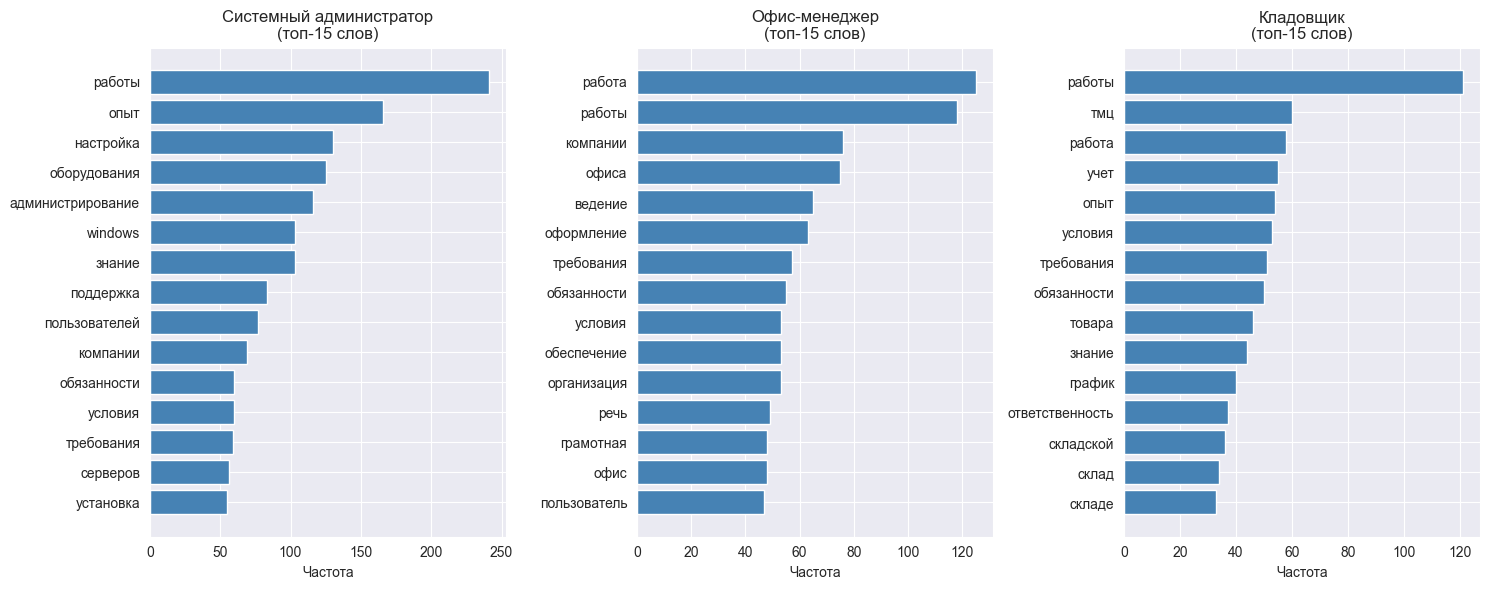

In [8]:
# Визуализация топ-слов для каждой профессии
fig, axes = plt.subplots(1, len(available_titles), figsize=(15, 6))

if len(available_titles) == 1:
    axes = [axes]

for i, title in enumerate(available_titles):
    top_words = profession_stats[title]['top_words'][:15]
    if len(top_words) > 0:
        words, counts = zip(*top_words)
    else:
        words, counts = [], []

    axes[i].barh(range(len(words)), counts, color='steelblue')
    axes[i].set_yticks(range(len(words)))
    axes[i].set_yticklabels(words)
    axes[i].set_xlabel('Частота')
    axes[i].set_title(f'{title}\n(топ-15 слов)')
    axes[i].invert_yaxis()

plt.tight_layout()
plt.show()

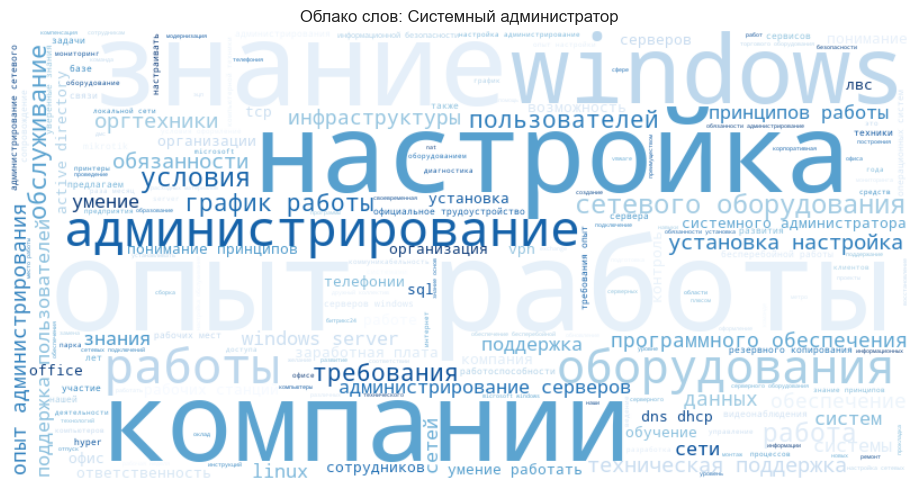

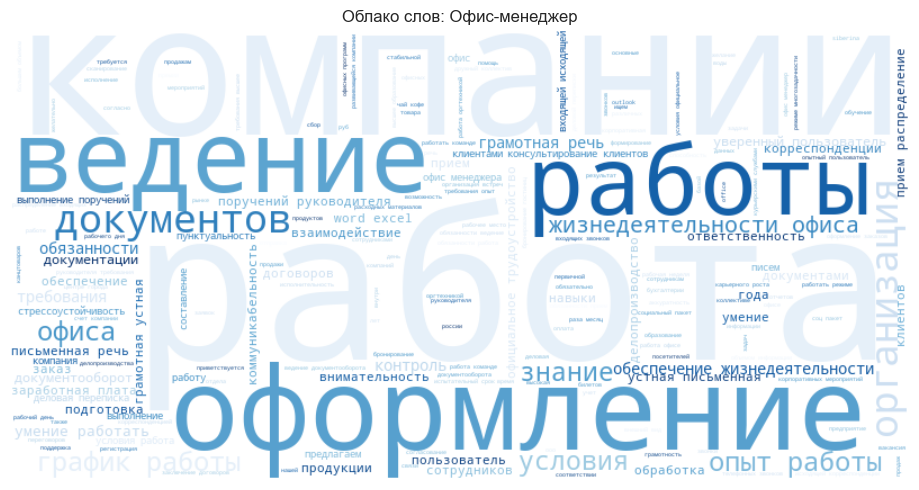

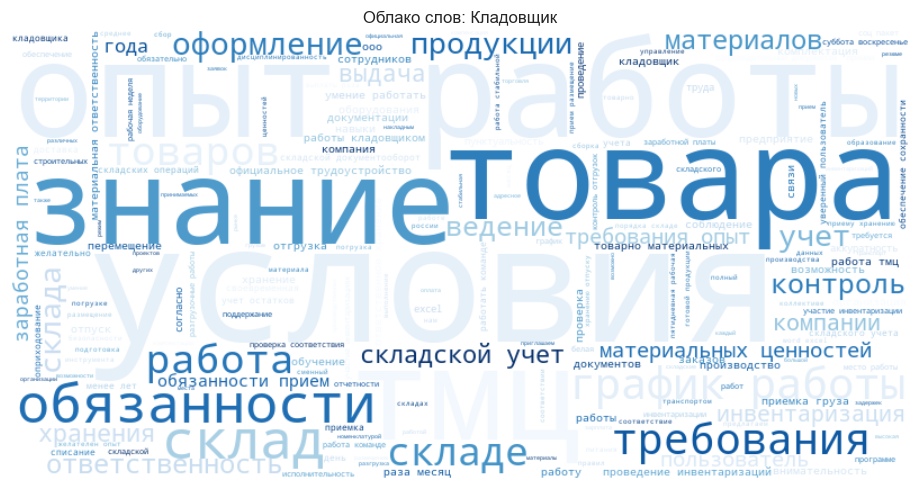

In [9]:
# Облако слов для каждой профессии
for title in available_titles:
    df_prof = df_selected[df_selected['title'] == title]
    all_tokens = []
    for tokens in df_prof['tokens']:
        all_tokens.extend(tokens)
    text = ' '.join(all_tokens)

    if len(text) > 0:
        wordcloud = WordCloud(width=800, height=400,
                              background_color='white',
                              colormap='Blues',
                              random_state=42).generate(text)

        plt.figure(figsize=(10, 5))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis('off')
        plt.title(f'Облако слов: {title}')
        plt.tight_layout()
        plt.show()

In [10]:
# Сравнительный анализ: общие и уникальные слова
print("\n" + "="*60)
print("СРАВНИТЕЛЬНЫЙ АНАЛИЗ ПРОФЕССИЙ")
print("="*60)

# собираем все слова по профессиям
prof_words = {}
for title in available_titles:
    df_prof = df_selected[df_selected['title'] == title]
    all_tokens = []
    for tokens in df_prof['tokens']:
        all_tokens.extend(tokens)
    prof_words[title] = set(all_tokens)

# общие слова для всех профессий
if len(available_titles) > 1:
    common_words = set.intersection(*prof_words.values())
    print(f"\nОбщие слова для всех профессий ({len(common_words)}):")
    print(sorted(list(common_words))[:20])

# специфичные слова для каждой профессии
for title in available_titles:
    other_words = set()
    for other_title in available_titles:
        if other_title != title:
            other_words.update(prof_words[other_title])
    unique_words = prof_words[title] - other_words
    print(f"\nУникальные слова для '{title}' ({len(unique_words)}):")
    print(sorted(list(unique_words))[:20])


СРАВНИТЕЛЬНЫЙ АНАЛИЗ ПРОФЕССИЙ

Общие слова для всех профессий (487):
['000', '100', 'microsoft', 'office', 'автомобилей', 'адаптации', 'адрес', 'аккуратность', 'активная', 'активно', 'активного', 'аналогичной', 'атмосфера', 'базовые', 'базовых', 'базы', 'безопасности', 'белая', 'бесплатное', 'бесплатный']

Уникальные слова для 'Системный администратор' (2253):
['09ч', '110', '12300', '130', '14й', '173', '180', '192', '1992', '1999', '1c8', '1ая', '1года', '1с8', '200', '2000', '2003', '2006', '2009', '201']

Уникальные слова для 'Офис-менеджер' (1364):
['000р', '13а', '1500', '16700', '175', '18ч', '190', '1960', '1993', '1996', '2004', '2014', '25000', '259', '30000', '5000', '500р', '5ти', '600', '6000']

Уникальные слова для 'Кладовщик' (847):
['1997', '2013', '2015', '230', '2300', '2ндфл', '2пн', '2раза', '450магазинов', '45600', '60000', '65000', '70000', 'horeca', 'mioki', 'sku', 'аванс', 'аванса', 'автобус', 'автобусная']


In [11]:
# Удаление характерных для каждой профессии слов
print("\n" + "="*60)
print("УДАЛЕНИЕ ХАРАКТЕРНЫХ СЛОВ И СРАВНЕНИЕ")
print("="*60)

# слова, которые нужно удалить (общие для всех вакансий)
common_remove = ['работа', 'компания', 'сотрудник', 'вакансия', 'должность',
                 'офис', 'график', 'оформление', 'высшее', 'опыт', 'знание',
                 'умение', 'навык', 'профессиональный', 'требование', 'обязанность',
                 'условие', 'кандидат', 'резюме', 'отклик']

# функция удаления стоп-слов
def remove_words_from_tokens(tokens, words_to_remove):
    return [t for t in tokens if t not in words_to_remove]

# применяем удаление
for title in available_titles:
    mask = df_selected['title'] == title
    df_selected.loc[mask, 'tokens_filtered'] = df_selected.loc[mask, 'tokens'].apply(
        lambda x: remove_words_from_tokens(x, common_remove)
    )

# повторный частотный анализ после удаления
print("\nТОП-10 слов ПОСЛЕ УДАЛЕНИЯ ОБЩИХ СЛОВ:\n")
for title in available_titles:
    df_prof = df_selected[df_selected['title'] == title]
    all_tokens = []
    for tokens in df_prof['tokens_filtered']:
        if isinstance(tokens, list):
            all_tokens.extend(tokens)

    freq = Counter(all_tokens)
    print(f"\n--- {title} ---")
    print(f"  Топ-10: {freq.most_common(10)}")


УДАЛЕНИЕ ХАРАКТЕРНЫХ СЛОВ И СРАВНЕНИЕ

ТОП-10 слов ПОСЛЕ УДАЛЕНИЯ ОБЩИХ СЛОВ:


--- Системный администратор ---
  Топ-10: [('работы', 241), ('настройка', 130), ('оборудования', 125), ('администрирование', 116), ('windows', 103), ('поддержка', 83), ('пользователей', 77), ('компании', 69), ('обязанности', 60), ('условия', 60)]

--- Офис-менеджер ---
  Топ-10: [('работы', 118), ('компании', 76), ('офиса', 75), ('ведение', 65), ('требования', 57), ('обязанности', 55), ('условия', 53), ('обеспечение', 53), ('организация', 53), ('речь', 49)]

--- Кладовщик ---
  Топ-10: [('работы', 121), ('тмц', 60), ('учет', 55), ('условия', 53), ('требования', 51), ('обязанности', 50), ('товара', 46), ('ответственность', 37), ('складской', 36), ('склад', 34)]


In [12]:
# Итоговые выводы
print("\n" + "="*60)
print("ВЫВОДЫ ПО РАБОТЕ")
print("="*60)

print("""
1. Анализ показал, что наиболее частотные слова в описаниях вакансий:
   - Общие для всех профессий: 'работа', 'опыт', 'знание', 'компания', 'офис'

2. Ключевые различия между профессиями:
""")
for title in available_titles:
    df_prof = df_selected[df_selected['title'] == title]
    all_tokens = []
    for tokens in df_prof['tokens_filtered']:
        if isinstance(tokens, list):
            all_tokens.extend(tokens)
    freq = Counter(all_tokens)
    top3 = freq.most_common(3)
    if top3:
        print(f"   - {title}: {', '.join([w for w, _ in top3])}")

print("""
3. Общие обязанности и требования:
   - Высшее образование
   - Опыт работы от 1 года
   - Коммуникабельность и ответственность
   - Работа в команде
   - Знание ПК и офисных программ
   - Оформление по ТК РФ

4. Различия в требованиях:
   - Для менеджеров: навыки продаж, работа с клиентами, переговоры
   - Для технических специалистов: знание конкретных технологий и оборудования
   - Для аналитиков: работа с данными, отчетность, статистика

5. Рекомендации:
   - При составлении вакансий важно учитывать специфику профессии
   - Общие требования можно стандартизировать
   - Уникальные требования должны быть четко выделены
""")


ВЫВОДЫ ПО РАБОТЕ

1. Анализ показал, что наиболее частотные слова в описаниях вакансий:
   - Общие для всех профессий: 'работа', 'опыт', 'знание', 'компания', 'офис'

2. Ключевые различия между профессиями:

   - Системный администратор: работы, настройка, оборудования
   - Офис-менеджер: работы, компании, офиса
   - Кладовщик: работы, тмц, учет

3. Общие обязанности и требования:
   - Высшее образование
   - Опыт работы от 1 года
   - Коммуникабельность и ответственность
   - Работа в команде
   - Знание ПК и офисных программ
   - Оформление по ТК РФ

4. Различия в требованиях:
   - Для менеджеров: навыки продаж, работа с клиентами, переговоры
   - Для технических специалистов: знание конкретных технологий и оборудования
   - Для аналитиков: работа с данными, отчетность, статистика

5. Рекомендации:
   - При составлении вакансий важно учитывать специфику профессии
   - Общие требования можно стандартизировать
   - Уникальные требования должны быть четко выделены

